<a href="https://colab.research.google.com/github/SaharaAli16/UNT_Teaching/blob/main/DTSC_4050/Week_14_Unsupervised_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DTSC 4050 — Lesson 11: Bayes' Rule and Unsupervised Learning
**Learning goals:** (1) update a probability using evidence; (2) reduce high-dimensional features to two PCA components; (3) discover groups without using target labels; (4) compare cluster quality;

Run the cells in order.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.manifold import TSNE
from scipy.cluster.hierarchy import linkage, dendrogram

RANDOM_STATE = 42
plt.rcParams['figure.figsize'] = (7, 4.5)


## Part 1 — Bayes' Rule: a simple student example
Imagine **100 students**:
- 60 are second-year students; 30 of those declared a major.
- 40 are third-year students; 32 of those declared a major.

**Question:** If a student has declared a major, what is the probability they are a third-year student?

**Prior:** P(third year) = 0.40  
**Likelihood:** P(declared | third year) = 0.80  
**Marginal:** P(declared) = 0.60 × 0.50 + 0.40 × 0.80 = 0.62  
**Posterior:** P(third year | declared) = (prior × likelihood) / marginal.

In [2]:
prior_third = 0.40
likelihood_declared_given_third = 0.80
prior_second = 0.60
likelihood_declared_given_second = 0.50

marginal_declared = (prior_second * likelihood_declared_given_second
                     + prior_third * likelihood_declared_given_third)
posterior_third_given_declared = (prior_third * likelihood_declared_given_third) / marginal_declared
print(f"Marginal P(declared): {marginal_declared:.2%}")
print(f"Posterior P(third year | declared): {posterior_third_given_declared:.2%}")
print("Check by counting:", 32 / (30 + 32))


Marginal P(declared): 62.00%
Posterior P(third year | declared): 51.61%
Check by counting: 0.5161290322580645


## Part 2 — Unsupervised learning
In supervised learning we train with a target label. In **unsupervised learning**, the algorithm searches for patterns in the feature measurements themselves.

We'll use the built-in **Iris** flower dataset (four numerical measurements per flower). The dataset includes species labels, but **we will not use those labels to fit PCA or clustering**. We can use them later only to help interpret visualizations.


In [3]:
iris = load_iris(as_frame=True)
X = iris.data.copy()
species = pd.Series(iris.target, name='species')
display(X.head())
print('Shape:', X.shape)
print('Missing values:', X.isna().sum().sum())
display(X.describe().round(2))


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


Shape: (150, 4)
Missing values: 0


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


## Part 3 — Standardize features
A feature measured on a larger numerical scale can dominate distance-based methods. Standardization makes each feature have approximately mean 0 and standard deviation 1.

In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print('Feature means after scaling:', np.round(X_scaled.mean(axis=0), 3))
print('Feature standard deviations:', np.round(X_scaled.std(axis=0), 3))


Feature means after scaling: [-0. -0. -0. -0.]
Feature standard deviations: [1. 1. 1. 1.]


## Part 4 — PCA: four dimensions → two
**Principal Component Analysis (PCA)** constructs new axes that capture as much variation as possible. The first component captures the most variance; the second captures the most remaining variance, subject to being perpendicular to the first.

Explained variance ratio: [0.73  0.229]
Total variance captured: 95.8%


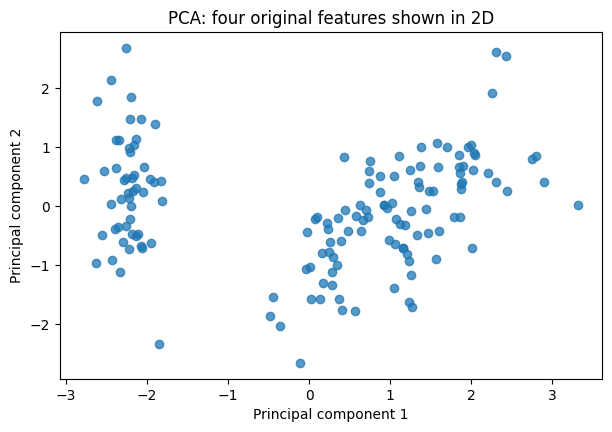

In [5]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
print('Explained variance ratio:', np.round(pca.explained_variance_ratio_, 3))
print('Total variance captured:', f'{pca.explained_variance_ratio_.sum():.1%}')
plt.scatter(X_pca[:,0], X_pca[:,1], alpha=.75)
plt.xlabel('Principal component 1')
plt.ylabel('Principal component 2')
plt.title('PCA: four original features shown in 2D')
plt.show()


,PC1,PC2
sepal length (cm),0.521,0.377
sepal width (cm),-0.269,0.923
petal length (cm),0.580,0.024
petal width (cm),0.565,0.067


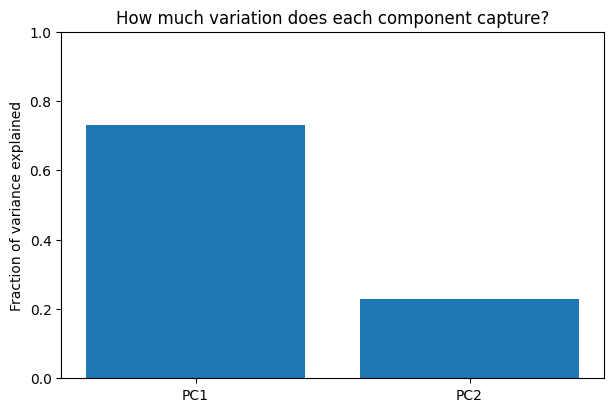

In [6]:
loadings = pd.DataFrame(pca.components_.T, index=X.columns, columns=['PC1', 'PC2'])
display(loadings.round(3))
plt.bar(['PC1','PC2'], pca.explained_variance_ratio_)
plt.ylabel('Fraction of variance explained')
plt.title('How much variation does each component capture?')
plt.ylim(0,1)
plt.show()


## Part 5 — K-means clustering
K-means assigns observations to **K groups** and repeatedly updates each group's center (centroid). Here we cluster the **standardized original features**, not the 2D PCA plot.

Cluster sizes: [53 50 47]


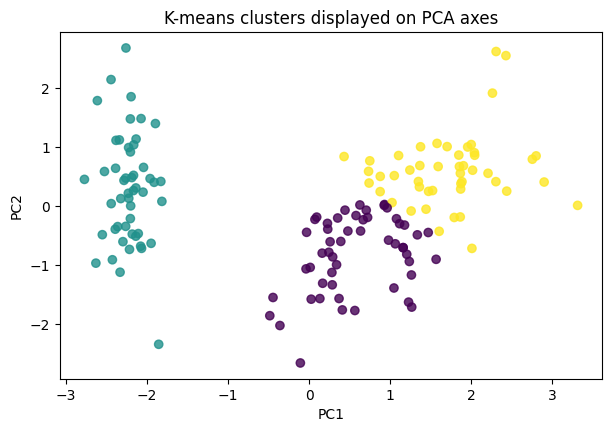

In [7]:
kmeans = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)
print('Cluster sizes:', np.bincount(kmeans_labels))
plt.scatter(X_pca[:,0], X_pca[:,1], c=kmeans_labels, cmap='viridis', alpha=.8)
plt.xlabel('PC1'); plt.ylabel('PC2')
plt.title('K-means clusters displayed on PCA axes')
plt.show()


### Choosing K: inertia and silhouette
- **Inertia** measures within-cluster squared distances; it usually decreases as K increases.
- **Silhouette score** compares how close a point is to its own cluster versus other clusters. Higher is generally better (maximum 1).
- Neither metric guarantees the clusters are scientifically meaningful.

,K,inertia,silhouette
0,2,222.362,0.582
1,3,139.820,0.460
2,4,114.093,0.387
3,5,90.928,0.346


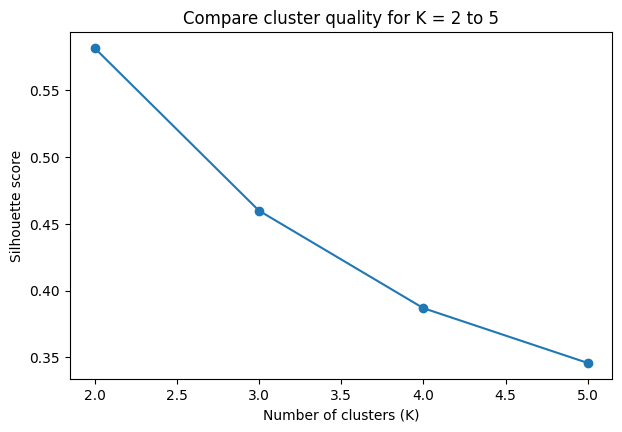

In [8]:
results = []
for k in range(2, 6):
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = model.fit_predict(X_scaled)
    results.append({'K':k, 'inertia':model.inertia_,
                    'silhouette':silhouette_score(X_scaled, labels)})
scores = pd.DataFrame(results)
display(scores.round(3))
fig, ax = plt.subplots()
ax.plot(scores['K'], scores['silhouette'], marker='o')
ax.set(xlabel='Number of clusters (K)', ylabel='Silhouette score',
       title='Compare cluster quality for K = 2 to 5')
plt.show()


## Part 6 — Hierarchical (agglomerative) clustering
Agglomerative clustering starts with individual observations and **merges** similar groups. A dendrogram shows when merges occur. For readability, the dendrogram below uses a small subset of 20 flowers.

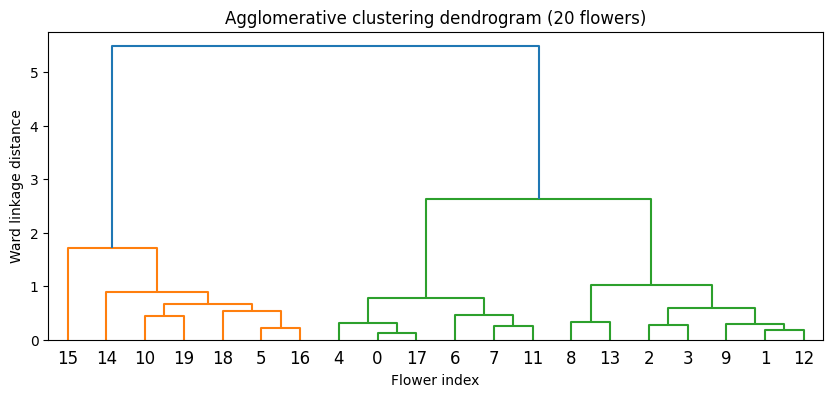

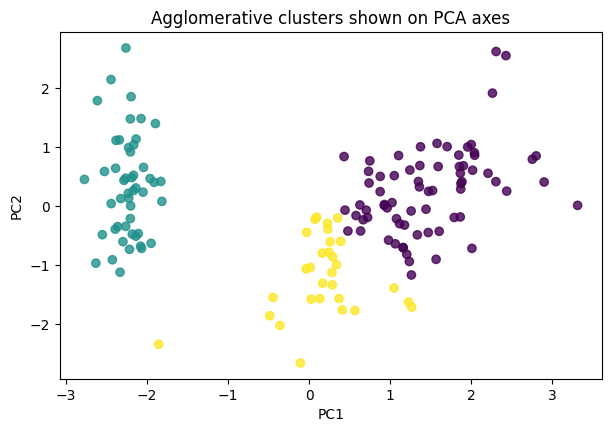

Agglomerative silhouette: 0.447


In [9]:
sample = X_scaled[:20]
Z = linkage(sample, method='ward')
plt.figure(figsize=(10,4))
dendrogram(Z, labels=[str(i) for i in range(20)])
plt.title('Agglomerative clustering dendrogram (20 flowers)')
plt.xlabel('Flower index'); plt.ylabel('Ward linkage distance')
plt.show()
hier = AgglomerativeClustering(n_clusters=3, linkage='ward')
hier_labels = hier.fit_predict(X_scaled)
plt.scatter(X_pca[:,0], X_pca[:,1], c=hier_labels, cmap='viridis', alpha=.8)
plt.xlabel('PC1'); plt.ylabel('PC2')
plt.title('Agglomerative clusters shown on PCA axes')
plt.show()
print('Agglomerative silhouette:', round(silhouette_score(X_scaled, hier_labels), 3))
